# LDA topic models: Weibo users
Fit six topic counts to the preprocessed marriage-discussion corpus. Each result is saved separately.

## 1. Load the data
Use the existing `tokens` and `year` columns; the source CSV is not changed.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

project = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "notebook").is_dir() and (p / "data").is_dir())
source = project / "data" / "weibo_posts_analysis.csv"
output = project / "data" / "analysis_results" / "lda_weibo_posts"
(project / "data" / "generated_figures" / output.relative_to(project / "data" / "analysis_results")).mkdir(parents=True, exist_ok=True)
(project / "data" / "model_cache" / output.relative_to(project / "data" / "analysis_results")).mkdir(parents=True, exist_ok=True)
output.mkdir(parents=True, exist_ok=True)
data = pd.read_csv(source, usecols=["tokens", "year"]).dropna(subset=["tokens"]).reset_index(drop=True)
texts = data["tokens"]
print(f"Documents loaded: {len(data):,}")


Documents loaded: 21,945


## 2. Count words
Use the preprocessed words. Keep words found in at least 10 documents, and cap the vocabulary at 5,000 words.

In [2]:
vectorizer = CountVectorizer(
    tokenizer=str.split, token_pattern=None, lowercase=False,
    min_df=10, max_df=0.85, max_features=5000
)
X = vectorizer.fit_transform(texts)
keep = X.getnnz(axis=1) > 0
X = X[keep]
data = data.loc[keep].reset_index(drop=True)
words = vectorizer.get_feature_names_out()
print(f"Documents used: {X.shape[0]:,}; vocabulary: {X.shape[1]:,} words")


Documents used: 21,938; vocabulary: 5,000 words


## 3. Fit and save the models
Try 8, 10, 12, 15, 20, and 25 topics. Each table shows the top 10 words for every topic. Compare whether the topics are clear and distinct; more topics are not automatically better.

In [3]:
topic_counts = [8, 10, 12, 15, 20, 25]
for k in topic_counts:
    model = LatentDirichletAllocation(
        n_components=k, learning_method="online", max_iter=12,
        batch_size=512, random_state=42, n_jobs=4
    )
    model.fit(X)
    top_indices = model.components_.argsort(axis=1)[:, -10:][:, ::-1]
    table = pd.DataFrame(words[top_indices], columns=[f"keyword_{i}" for i in range(1, 11)])
    table.insert(0, "topic", range(1, k + 1))
    if k == 12:
        k12_probabilities = model.transform(X)
        k12_keywords = table.copy()
    table.to_csv(output / f"k{k}_top10_keywords.csv", index=False, encoding="utf-8-sig")
    print(f"{k} topics — saved to {output / f'k{k}_top10_keywords.csv'}")
    display(table)


8 topics — saved to /Users/jingwenzhai/Desktop/Fightin Words/结果/lda_weibo_posts/k8_top10_keywords.csv


,topic,keyword_1,keyword_2,keyword_3,keyword_4,keyword_5,keyword_6,keyword_7,keyword_8,keyword_9,keyword_10
0,1,婚姻,离婚,离婚冷静期,爱情,结婚,感情,夫妻,晚婚,婚姻登记,丈夫
1,2,女性,社会,不婚,恐婚恐育,孩子,男性,结婚,生育,恐婚,年轻人
2,3,喜欢,感觉,朋友,恋爱,开心,好像,相亲,希望,工作,妈妈
3,4,彩礼,孩子,结婚,男人,女儿,老公,父母,女人,房子,妈妈
4,5,生活,结婚,幸福,婚姻,人生,希望,喜欢,爱情,伴侣,选择
5,6,催婚,结婚,我妈,相亲,不结婚,对象,谈恋爱,年纪,亲戚,焦虑
6,7,家庭,父母,工作,关系,婚恋,男人,选择,生活,能力,感情
7,8,结婚,恐婚,晚婚,晚上,朋友,上班,婚礼,不婚,同事,同学


10 topics — saved to /Users/jingwenzhai/Desktop/Fightin Words/结果/lda_weibo_posts/k10_top10_keywords.csv


,topic,keyword_1,keyword_2,keyword_3,keyword_4,keyword_5,keyword_6,keyword_7,keyword_8,keyword_9,keyword_10
0,1,婚姻,生活,人生,爱情,工作,选择,希望,晚婚,时间,努力
1,2,女性,不婚,社会,孩子,婚姻,男性,结婚,生育,年轻人,选择
2,3,喜欢,相亲,朋友,恋爱,对象,单身,感觉,工作,开心,分手
3,4,彩礼,男人,女人,结婚,孩子,女儿,老公,房子,女生,儿子
4,5,喜欢,结婚,幸福,希望,感觉,恋爱,生活,永远,害怕,伴侣
5,6,催婚,结婚,妈妈,我妈,父母,家里,爸妈,不结婚,亲戚,工作
6,7,父母,家庭,婚姻,关系,感情,婚恋,能力,价值,选择,情绪
7,8,恐婚,结婚,孩子,晚上,感觉,老公,上班,日常,朋友,回家
8,9,结婚,恐婚恐育,孩子,爸爸,婚礼,妈妈,姐姐,老师,回来,幸福
9,10,离婚,离婚冷静期,结婚,婚姻,婚姻登记,丈夫,夫妻,家暴,妻子,冷静


12 topics — saved to /Users/jingwenzhai/Desktop/Fightin Words/结果/lda_weibo_posts/k12_top10_keywords.csv


...

,topic,keyword_1,keyword_2,keyword_3,keyword_4,keyword_5,keyword_6,keyword_7,keyword_8,keyword_9,keyword_10
0,1,生活,工作,好像,人生,开心,希望,一年,时间,朋友,感觉
1,2,女性,恐婚,社会,男性,生育,孩子,年轻人,中国,结婚,发展
2,3,催婚,结婚,男朋友,恋爱,女朋友,喜欢,家里,讨厌,感觉,回家
3,4,彩礼,男人,女人,男方,女方,女孩,老婆,女儿,房子,娶
4,5,喜欢,恋爱,谈恋爱,感觉,世界,希望,永远,单身,自由,想要
5,6,分手,男友,上海,不婚,两人,闺蜜,前任,有人,公司,不育
6,7,家庭,关系,婚恋,父母,婚姻,选择,能力,价值,生活,一种
7,8,幸福,不婚主义,母亲,结婚,父亲,早婚,游戏,不幸福,坚定,信息
8,9,晚上,恐婚恐育,婚礼,第一次,老师,吃饭,回来,回家,感觉,明天
9,10,离婚,离婚冷静期,结婚,婚姻登记,婚姻,夫妻,丈夫,家暴,妻子,法律


20 topics — saved to /Users/jingwenzhai/Desktop/Fightin Words/结果/lda_weibo_posts/k20_top10_keywords.csv


,topic,keyword_1,keyword_2,keyword_3,keyword_4,keyword_5,keyword_6,keyword_7,keyword_8,keyword_9,keyword_10
0,1,生活,人生,工作,好像,选择,希望,结婚,时间,婚姻,朋友
1,2,女性,社会,男性,生育,婚恋,年轻人,中国,家庭,经济,孩子
2,3,婚姻,爱情,感情,恋爱,关系,永远,期待,一段,美好,幸福
3,4,男人,女人,老公,男方,老婆,女孩,房子,孩子,女生,女方
4,5,幸福,喜欢,感觉,希望,恋爱,世界,结婚,羡慕,想要,一生
5,6,分手,有人,明明,爷爷,前任,恋爱,闺蜜,挽回,心动,震惊
6,7,父母,家庭,孩子,生活,能力,情绪,理解,关系,接受,想法
7,8,不婚,晚婚,焦虑,不婚主义,结婚,不育,婚恋,年龄,早婚,现实
8,9,恐婚,女儿,儿子,爸爸,爸妈,妈妈,结婚,幸福,阿姨,奶奶
9,10,离婚,离婚冷静期,结婚,婚姻登记,婚姻,丈夫,夫妻,家暴,法律,妻子


25 topics — saved to /Users/jingwenzhai/Desktop/Fightin Words/结果/lda_weibo_posts/k25_top10_keywords.csv


,topic,keyword_1,keyword_2,keyword_3,keyword_4,keyword_5,keyword_6,keyword_7,keyword_8,keyword_9,keyword_10
0,1,生活,人生,工作,希望,努力,时间,好像,经历,未来,朋友
1,2,女性,社会,男性,年轻人,生育,中国,婚恋,经济,家庭,价值
2,3,相亲,对象,十年,希望,不知,恋爱,再见,结束,依旧,见面
3,4,男人,女人,婚姻,女孩,有钱,女儿,恶心,出轨,嫁给,事业
4,5,结婚,爸爸,婚礼,永远,朋友,大学,男朋友,催生,参加,希望
5,6,分手,同事,公司,男友,一年,工作,情绪,领导,前任,单位
6,7,父母,家庭,能力,选择,工作,条件,价值,接受,关系,婚恋
7,8,不婚,不婚主义,焦虑,不育,现实,主义,坚定,不孕,理想,母亲
8,9,电影,医生,一部,真实,生命,善良,道德,位置,这部,一句
9,10,离婚,离婚冷静期,婚姻,婚姻登记,结婚,丈夫,夫妻,家暴,妻子,法律


## 4. Topic prevalence for K = 12
Prevalence is the average topic probability across documents. Each document has equal weight. The yearly table uses the same measure within each year.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Arial Unicode MS"
labels = [f"T{i + 1}  " + " · ".join(k12_keywords.iloc[i, 1:4]) for i in range(12)]
dominant = k12_probabilities.argmax(axis=1)
overall = pd.DataFrame({
    "topic": range(1, 13),
    "top_keywords": [" / ".join(k12_keywords.iloc[i, 1:11]) for i in range(12)],
    "prevalence_pct": (k12_probabilities.mean(axis=0) * 100).round(2),
    "dominant_documents": np.bincount(dominant, minlength=12),
})
overall["dominant_doc_pct"] = (overall["dominant_documents"] / len(data) * 100).round(2)
overall.to_csv(output / "k12_topic_prevalence.csv", index=False, encoding="utf-8-sig")

rows = []
for year in sorted(data["year"].dropna().astype(int).unique()):
    mask = data["year"].to_numpy() == year
    for topic, share in enumerate(k12_probabilities[mask].mean(axis=0), start=1):
        rows.append({"year": year, "topic": topic, "prevalence_pct": round(share * 100, 2),
                     "n_documents": int(mask.sum())})
yearly = pd.DataFrame(rows)
yearly.to_csv(output / "k12_topic_by_year.csv", index=False, encoding="utf-8-sig")
print("Overall topic prevalence (%)")
display(overall[["topic", "top_keywords", "prevalence_pct", "dominant_doc_pct"]])
print("Topic prevalence by year (%)")
display(yearly.pivot(index="topic", columns="year", values="prevalence_pct"))


Overall topic prevalence (%)


,topic,top_keywords,prevalence_pct,dominant_doc_pct
0,1,婚姻 / 生活 / 人生 / 选择 / 结婚 / 爱情 / 晚婚 / 经历 / 一生 / 世界,11.41,13.29
1,2,女性 / 社会 / 婚姻 / 婚恋 / 家庭 / 男性 / 生育 / 不婚 / 孩子 / 年轻人,7.95,7.91
2,3,喜欢 / 恋爱 / 谈恋爱 / 爱情 / 感觉 / 相亲 / 单身 / 特别 / 好像 / 讨厌,8.33,7.41
3,4,彩礼 / 男人 / 女人 / 女生 / 男生 / 男方 / 女孩 / 女方 / 结婚 / 娶,6.49,5.33
4,5,幸福 / 希望 / 结婚 / 朋友 / 开心 / 快乐 / 喜欢 / 生活 / 永远 / 伴侣,10.95,12.22
5,6,催婚 / 不婚 / 相亲 / 晚婚 / 我妈 / 对象 / 年纪 / 不结婚 / 父母 / 焦虑,7.26,6.41
6,7,关系 / 情绪 / 感情 / 伴侣 / 父母 / 一种 / 能力 / 自我 / 想法 / 想要,8.33,8.20
7,8,晚上 / 手机 / 单身 / 明天 / 睡觉 / 上班 / 东西 / 回家 / 感觉 / 本来,5.54,3.92
8,9,感觉 / 相亲 / 吃饭 / 晚上 / 老师 / 回来 / 对象 / 朋友 / 同学 / 回家,7.62,6.95
9,10,离婚 / 离婚冷静期 / 结婚 / 婚姻 / 婚姻登记 / 夫妻 / 丈夫 / 家暴 / 妻...,5.62,5.20


Topic prevalence by year (%)


year,2021,2022,2023,2024,2025
topic,,,,,
1,11.20,11.34,11.48,11.54,11.52
2,7.79,7.57,8.09,7.86,8.83
3,8.32,8.76,8.44,8.23,7.62
4,6.80,6.83,6.33,6.05,6.46
5,10.98,10.72,11.19,11.09,10.61
6,6.69,8.17,7.26,7.08,7.01
7,8.35,7.91,8.19,8.69,8.63
8,5.78,5.57,5.52,5.52,5.11
9,7.80,7.40,7.74,7.61,7.45


## 5. Make the charts
The bar chart shows overall topic prevalence. The heatmap shows how it changes by year. Topic labels use the first three keywords.

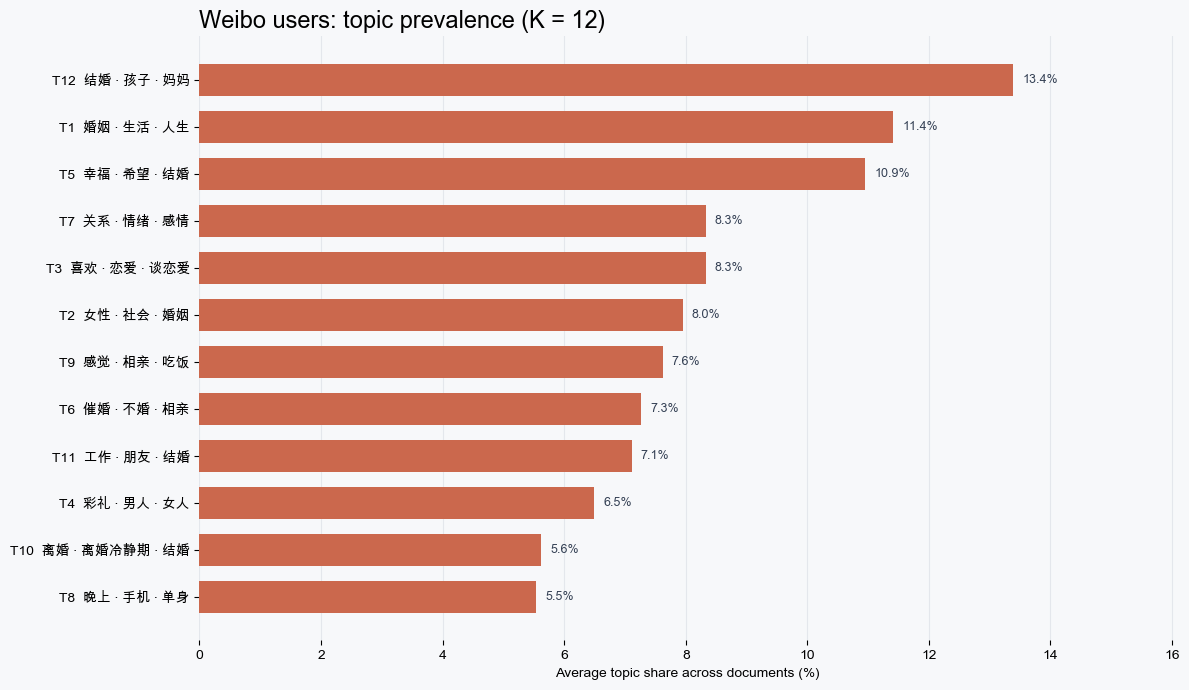

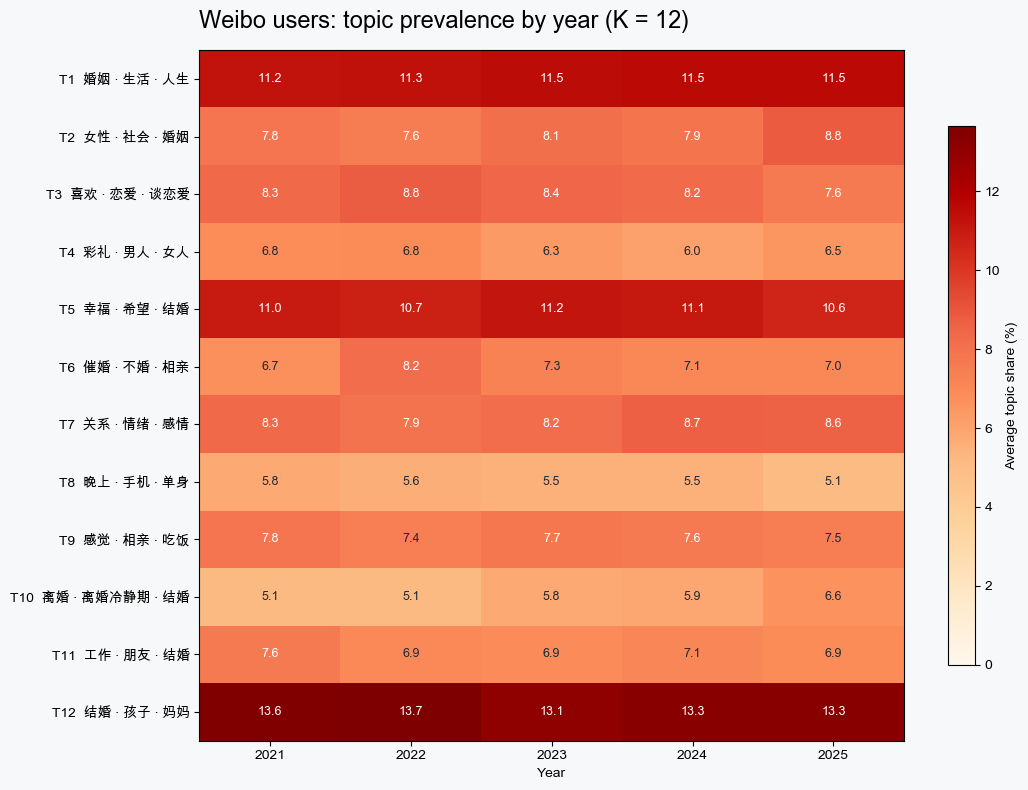

In [5]:
order = np.argsort(overall["prevalence_pct"].to_numpy())
fig, ax = plt.subplots(figsize=(12, 7), facecolor="#f7f8fa")
ax.set_facecolor("#f7f8fa")
ax.barh([labels[i] for i in order], overall["prevalence_pct"].iloc[order], color="#cb684d", height=0.68)
for y, value in enumerate(overall["prevalence_pct"].iloc[order]):
    ax.text(value + 0.15, y, f"{value:.1f}%", va="center", fontsize=9, color="#344054")
ax.set_xlim(0, overall["prevalence_pct"].max() * 1.20)
ax.set_xlabel("Average topic share across documents (%)")
ax.set_title("Weibo users: topic prevalence (K = 12)", loc="left", fontsize=17, fontweight="bold")
ax.grid(axis="x", color="#e4e7ec")
ax.set_axisbelow(True)
for spine in ax.spines.values(): spine.set_visible(False)
fig.tight_layout()
fig.savefig((project / "data" / "generated_figures" / output.relative_to(project / "data" / "analysis_results")) / "k12_topic_prevalence.png", dpi=180, facecolor=fig.get_facecolor())
plt.show()

grid = yearly.pivot(index="topic", columns="year", values="prevalence_pct").reindex(range(1, 13))
fig, ax = plt.subplots(figsize=(11, 8), facecolor="#f7f8fa")
image = ax.imshow(grid, cmap="OrRd", aspect="auto", vmin=0)
ax.set_xticks(range(len(grid.columns)), grid.columns)
ax.set_yticks(range(12), labels)
ax.set_xlabel("Year")
ax.set_title("Weibo users: topic prevalence by year (K = 12)", loc="left", fontsize=17, fontweight="bold", pad=16)
for row in range(12):
    for col in range(len(grid.columns)):
        value = grid.iloc[row, col]
        ax.text(col, row, f"{value:.1f}", ha="center", va="center",
                color="white" if value > grid.to_numpy().max() * 0.55 else "#1f2937", fontsize=9)
fig.colorbar(image, ax=ax, label="Average topic share (%)", shrink=0.78)
fig.tight_layout()
fig.savefig((project / "data" / "generated_figures" / output.relative_to(project / "data" / "analysis_results")) / "k12_topic_by_year.png", dpi=180, facecolor=fig.get_facecolor())
plt.show()
